# PR 1: Introduction to Visual Analytics and Visualization libraries in Python

# Lab goals:
In this lab, we will deep dive into how Visual Analytics and some of the most relevant Python libraries: matplotlib and seaborn.
We will apply these two libraries to EDA: Exploratory Data Analysis, a key stage in a Machine Learning project.

Use as reference information for both libraries:
- seaborn-> https://seaborn.pydata.org/
- matplotlib-> https://matplotlib.org/

In data visualization there are some web references as:
- https://datavizproject.com/
- https://www.data-to-viz.com/


### Due date: during the lab session. It is not allowed to send it after the session
### Submission procedure: via Moodle.
### Complete with your Name: Ander Barnadas
### Complete with your NIA: 286368

# 1 Environment setup and data gathering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

C:\Users\ander\AppData\Roaming\Python\Python312\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\ander\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
# Upload the dataset and store it in a tips variable.

In [3]:
tips = sns.load_dataset("tips")

**EX1** Print the top 5 and tail 5 of the dataset

In [4]:

display(tips.head())

display(tips.tail())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


,total_bill,tip,sex,smoker,day,time,size
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2
243,18.78,3.00,Female,No,Thur,Dinner,2


With .info() we can identify the structure of the dataframe: columns, types of variables and nulls.

In [5]:
tips.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


# 2 Exploratory Data Analysis (EDA)

## 2.1 Basics of EDA

**EX2** Is there any null in the dataframe?

In [6]:
tips.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

**Answer:** There are no missing values. Every column has 0 null values.

With .describe() we can obtain the main statistics of numerical variables

In [7]:
tips.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


**EX3** Apply .unique() to identify unique values in categorical variables

In [8]:
for column in ["sex", "smoker", "day", "time"]:
    print(column, tips[column].unique())

sex

 ['Female', 'Male']
Categories (2, str): ['Male', 'Female']
smoker ['No', 'Yes']
Categories (2, str): ['Yes', 'No']
day ['Sun', 'Sat', 'Thur', 'Fri']
Categories (4, str): ['Thur', 'Fri', 'Sat', 'Sun']
time ['Dinner', 'Lunch']
Categories (2, str): ['Lunch', 'Dinner']


**EX4** To complete the understanding of categorical variables, we need also to know how many samples by category in each variable. Use .value_count() to count the number of samples per *day*, *smoker* and *sex* categories

In [9]:
for column in ["day", "smoker", "sex"]:
    print(column)
    print(tips[column].value_counts())
    print()

day
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

smoker
smoker
No     151
Yes     93
Name: count, dtype: int64

sex
sex
Male      157
Female     87
Name: count, dtype: int64



## 2.2 Applying visualization to improve the EDA

Let's create an auxiliar variable, *aux*, that is the value_counts() of tips.day

In [10]:
aux=tips.day.value_counts()

As a series, we can access the category name using **aux.index** and the category values by **aux.values**

In [11]:
aux.index


CategoricalIndex(['Sat', 'Sun', 'Thur', 'Fri'], categories=['Thur', 'Fri', 'Sat', 'Sun'], ordered=False, dtype='category', name='day')

In [12]:
aux.values

array([87, 76, 62, 19])

**EX5** Let's create our first bar plot using the following code: i.e. plt.bar(x, height). Which is the day with more visits?

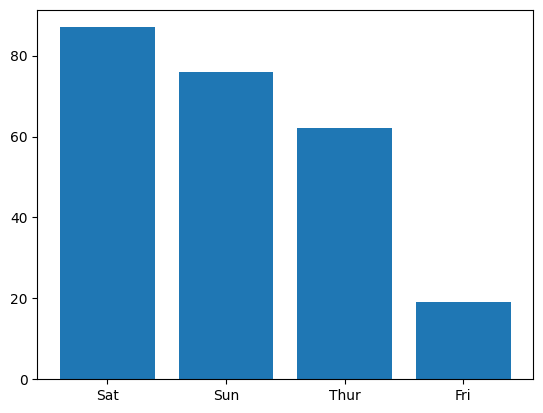

In [13]:
plt.figure()
plt.bar(x=aux.index,height=aux.values)
plt.show()

**Answer:** Saturday has the most visits: 87 records. Each row represents a table/bill, not an individual customer.

**EX6** Let's use several attributes of a bar plot. Create a new bar plot similar to the previous one with orange bars, no edgecolor, width of 0.4, align at the center the horizontal axis. Include also the legend.

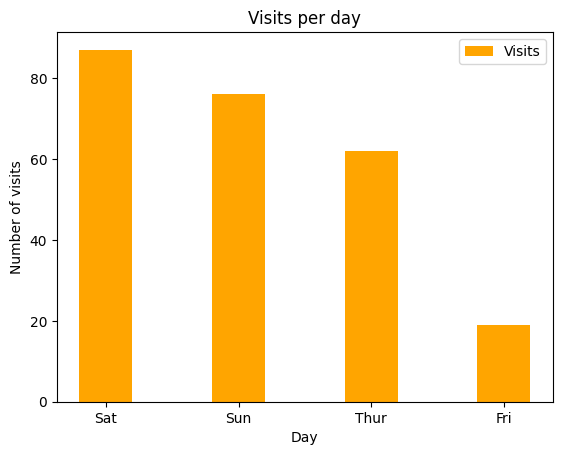

In [14]:
plt.figure()
plt.bar(aux.index, aux.values, color="orange", edgecolor="none",
        width=0.4, align="center", label="Visits")
plt.xlabel("Day")
plt.ylabel("Number of visits")
plt.title("Visits per day")
plt.legend()
plt.show()

**EX7** Repeat **EX6** but use color "grey" and rotation=90 in the x axis.

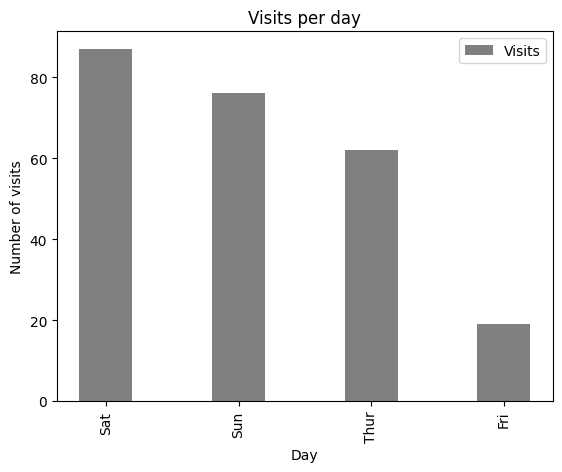

In [15]:
plt.figure()
plt.bar(aux.index, aux.values, color="grey", edgecolor="none",
        width=0.4, align="center", label="Visits")
plt.xticks(rotation=90)
plt.xlabel("Day")
plt.ylabel("Number of visits")
plt.title("Visits per day")
plt.legend()
plt.show()

**EX8** Repeat EX7 but with horizontal bars. Recall to use *plt.barh* instead of *plt.bar*. Use plt.yticks() to rotate the labels of y axis. Play with different rotation values.

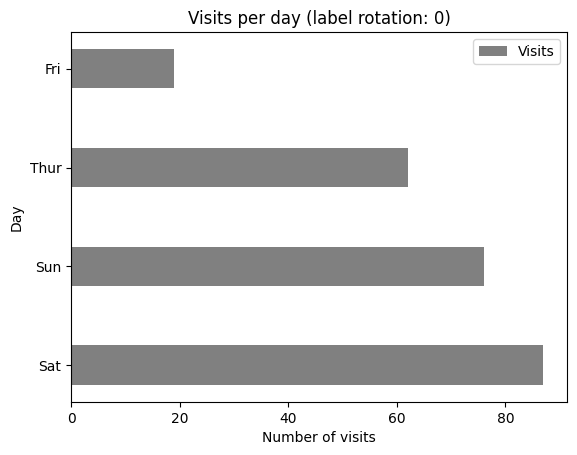

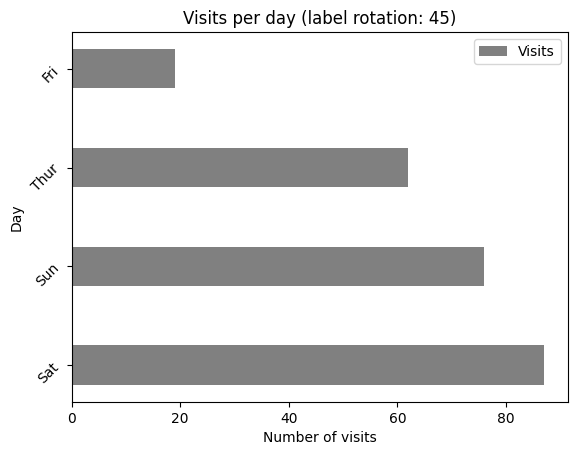

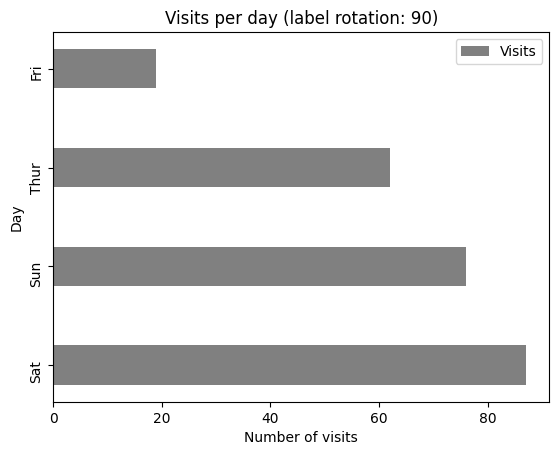

In [16]:
for rotation in [0, 45, 90]:
    plt.figure()
    plt.barh(aux.index, aux.values, color="grey", edgecolor="none",
             height=0.4, align="center", label="Visits")
    plt.yticks(rotation=rotation)
    plt.xlabel("Number of visits")
    plt.ylabel("Day")
    plt.title(f"Visits per day (label rotation: {rotation})")
    plt.legend()
    plt.show()

**EX9** Repeat EX6 with seaborn. Use **sns.countplot()**. Which is the main difference with barplot?

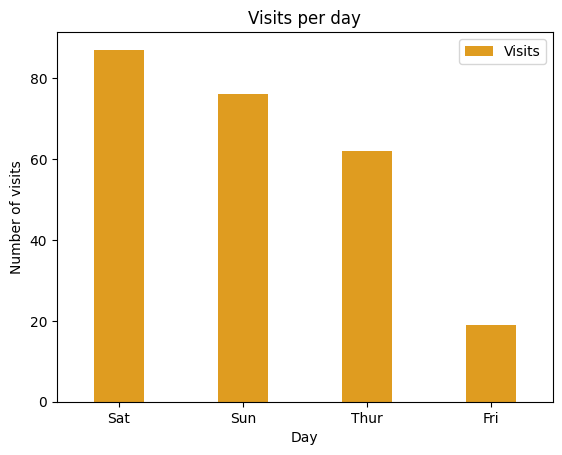

In [17]:
plt.figure()
sns.countplot(data=tips, x="day", order=aux.index, color="orange",
              edgecolor="none", width=0.4, label="Visits")
plt.xlabel("Day")
plt.ylabel("Number of visits")
plt.title("Visits per day")
plt.legend()
plt.show()

**Answer:** countplot counts the rows in each category automatically. With plt.bar, we supplied the counts ourselves. Seaborn barplot instead summarizes a numerical variable, using its mean by default.

**EX10** Let's apply sns.barplot(data=tips, x="day", y="total_bill"). Which is this code line returning? Tip: Compare the plot with the main statistics of "total_bill" for each of these days using *.describe()*.

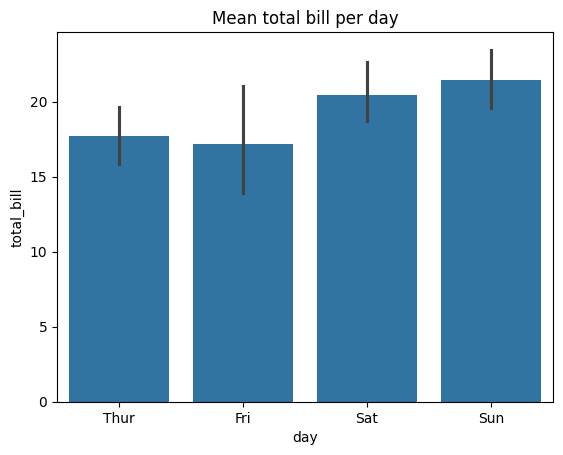

,count,mean,std,min,25%,50%,75%,max
day,,,,,,,,
Thur,62.0,17.682742,7.886170,7.51,12.4425,16.20,20.1550,43.11
Fri,19.0,17.151579,8.302660,5.75,12.0950,15.38,21.7500,40.17
Sat,87.0,20.441379,9.480419,3.07,13.9050,18.24,24.7400,50.81
Sun,76.0,21.410000,8.832122,7.25,14.9875,19.63,25.5975,48.17


In [18]:
plt.figure()
sns.barplot(data=tips, x="day", y="total_bill")
plt.title("Mean total bill per day")
plt.show()
tips.groupby("day", observed=True)["total_bill"].describe()

**Answer:** The height of each bar is the mean total bill for that day. The small lines show 95% confidence intervals for the means. The bar heights match the mean column in describe().

**EX11** Create a pie plot to represent the % of days with tips per each day. Use plt.pie() from matplotlib (Recall: aux.index represents the days and aux.values stores the number of days per day). Tip: Use autopct='%1.2f' as an attribute to show the ratio value in terms of '%'

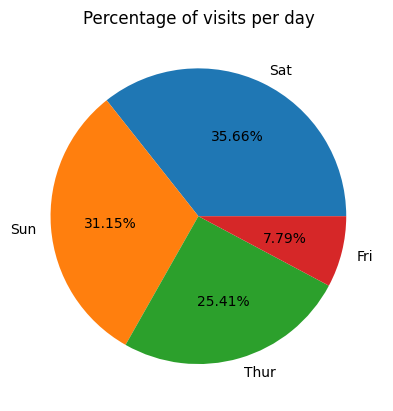

In [19]:
plt.figure()
plt.pie(aux.values, labels=aux.index, autopct="%1.2f%%")
plt.title("Percentage of visits per day")
plt.show()

If we want to control the color attribute of each piece of the pie, we can create a variable colors as follows:

In [20]:
color = plt.get_cmap('Blues')(np.linspace(0.2, 0.7, len(aux.index)))

**EX12** Now repeat the previous plot that includes the colors=color attribute and also the following ones: explode=[0.2,0,0,0] and radius=3. Which are the effects of these parameters into the plot?

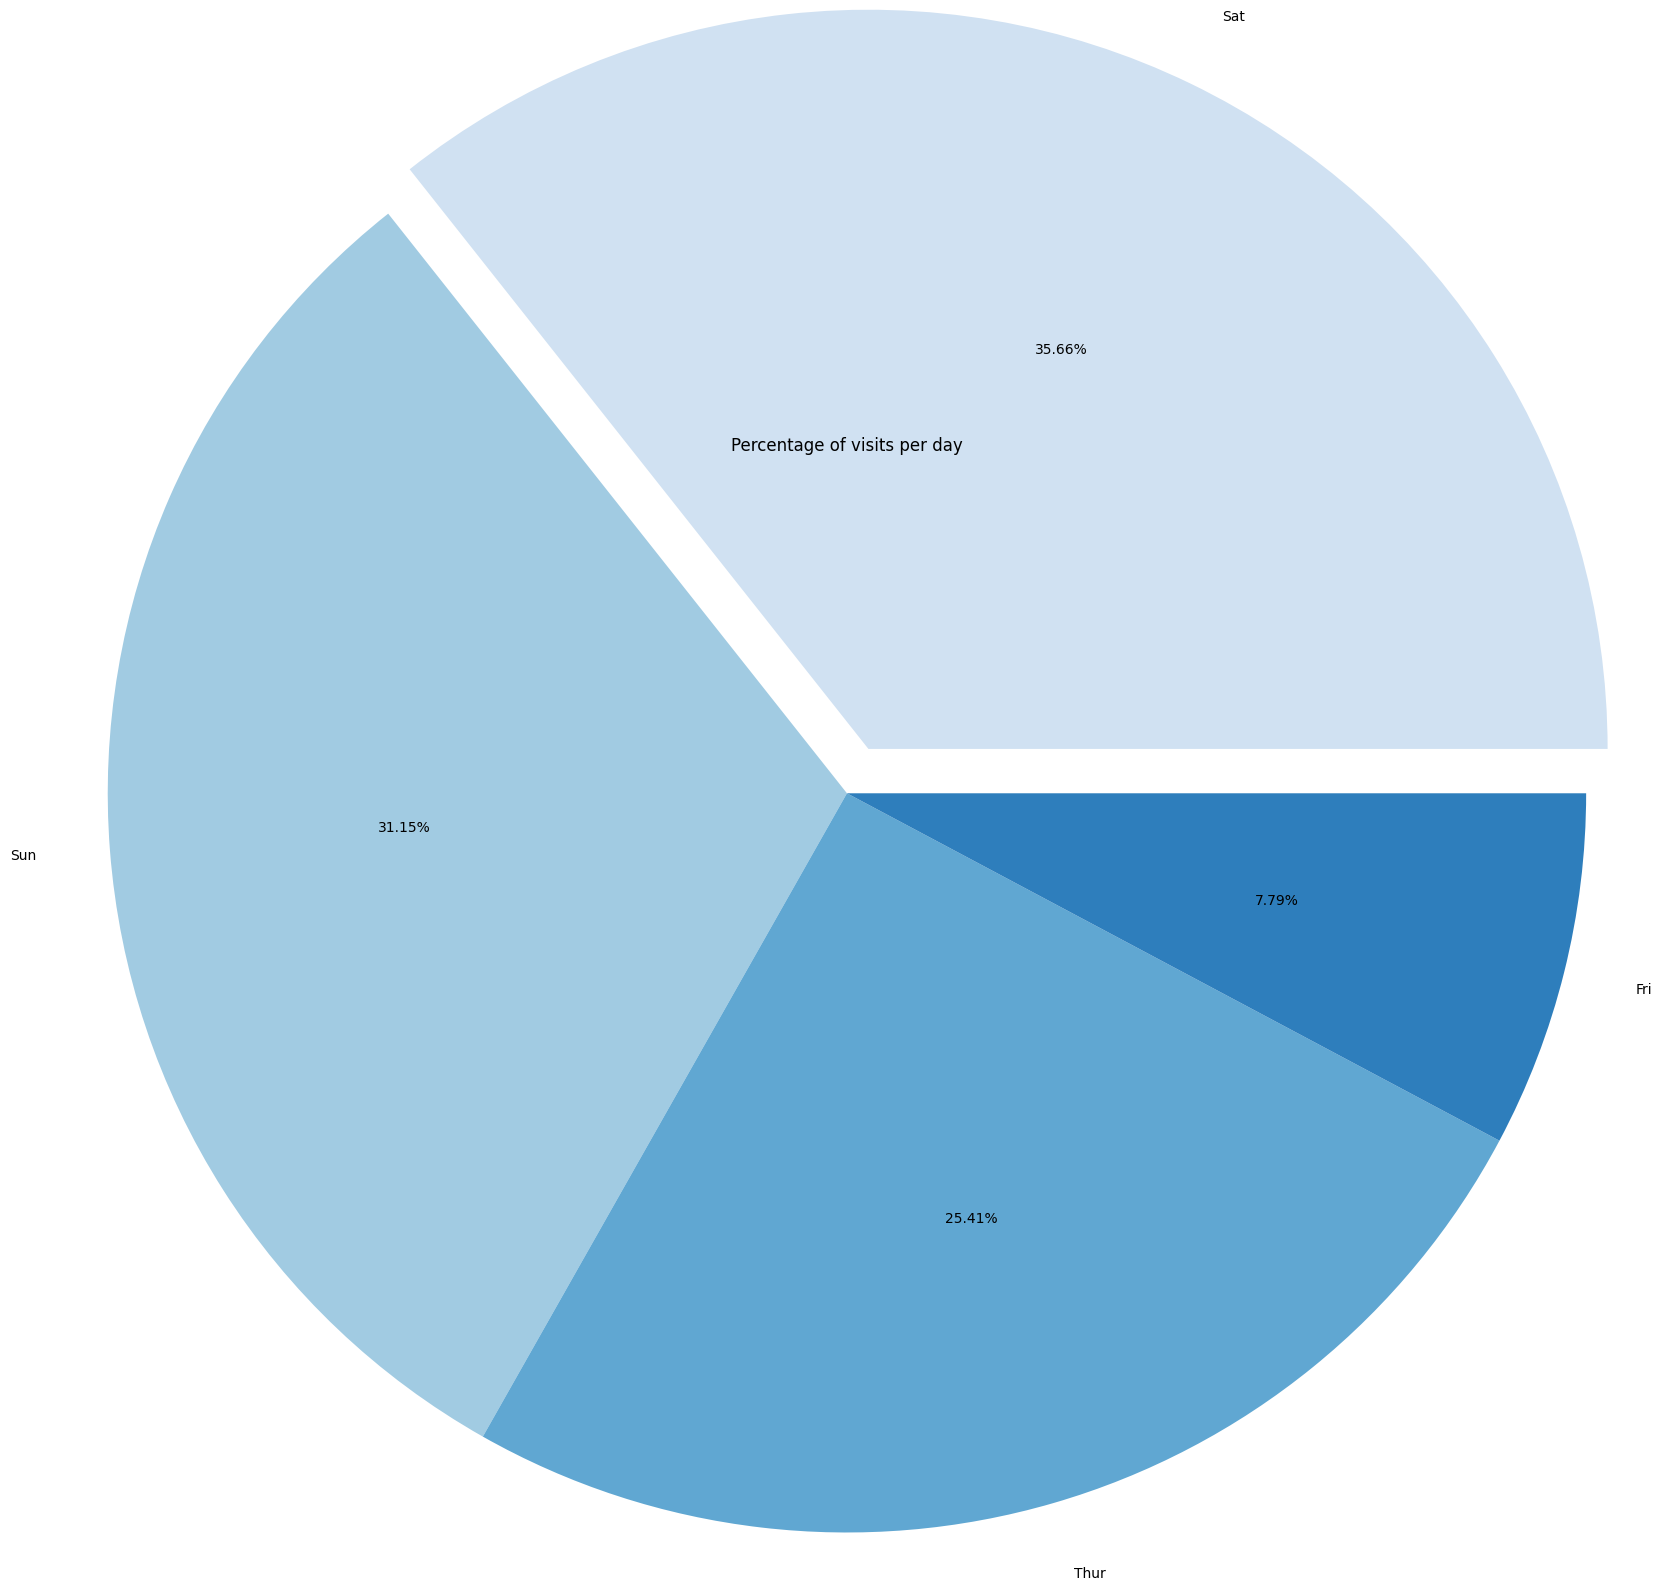

In [21]:
plt.figure(figsize=(8, 8))
plt.pie(aux.values, labels=aux.index, autopct="%1.2f%%",
        colors=color, explode=[0.2, 0, 0, 0], radius=3)
plt.title("Percentage of visits per day", pad=25)
plt.show()

**Answer:** colors sets the slice colors. explode moves the first slice (Saturday) away from the center by 0.2 times the radius. radius=3 makes the pie larger in plot coordinates; the figure size controls its size on screen.

## Distribution plots

**Histograms**:

*matplotlib function*: hist(x)
*parameters*:

- color: Set the color of the bars in the histogram.
- bins: Set the number of bins to display in the histogram, or specify speciic bins.



*seaborn function*: sns.displot(x)
*parameters*:

- color: Set the color of the bars in the histogram.
- kind: Approach for visualizing the data. Selects the underlying plotting function and determines the additional set of valid parameters.


**Boxplots**:

*matplotlib function*: boxplot(x)

*seaborn function*: sns.boxplot(x)

**Violin**: A violin plot plays a similar role as a box and whisker plot. It shows the distribution of quantitative data across several levels of one (or more) categorical variables such that those distributions can be compared. Unlike a box plot, in which all of the plot components correspond to actual datapoints, the violin plot features a kernel density estimation of the underlying distribution.

*matplotlib function*: violinplot(x)
*parameters*:
- showmeans: If True, will toggle rendering of the means.
- showextrema: If True, will toggle rendering of the extrema.
- showmedians: If True, will toggle rendering of the medians.

*seaborn function*: sns.violinplot(x)

**EX13** Execute this histogram plot and examine the results. What type of distribution this variable presents?

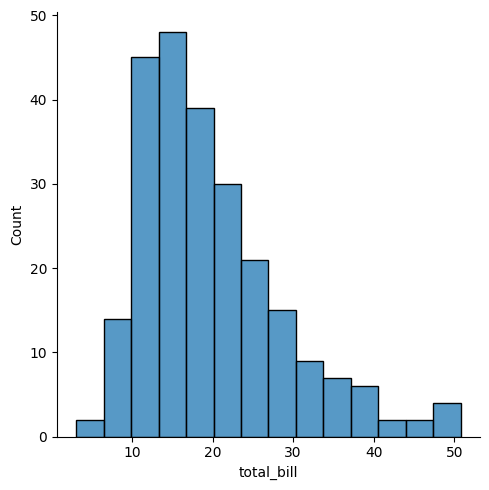

In [22]:
sns.displot(tips['total_bill'], kind="hist")

**Answer:** The total bill distribution is right-skewed. Most bills are small or medium, with a few large bills forming a long right tail.

**EX14** Repeat the previous exercise with matplotlib (i.e. plt.hist()). Enrich the visualization with orange colour and 150 bins. Add a title, X and Y axis names. Any issue in the visualization? How could you improve the distribution visualization?

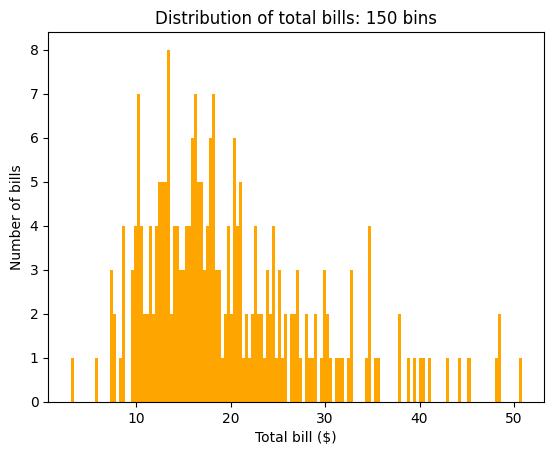

In [23]:
plt.figure()
plt.hist(tips["total_bill"], color="orange", bins=150)
plt.title("Distribution of total bills: 150 bins")
plt.xlabel("Total bill ($)")
plt.ylabel("Number of bills")
plt.show()

**Answer:** 150 bins is too many for 244 records. The bars are narrow and many bins are empty, so the overall shape is hard to see. Fewer bins make the distribution clearer.

**EX15** Fix the identified issue and repeat the previous exercise.

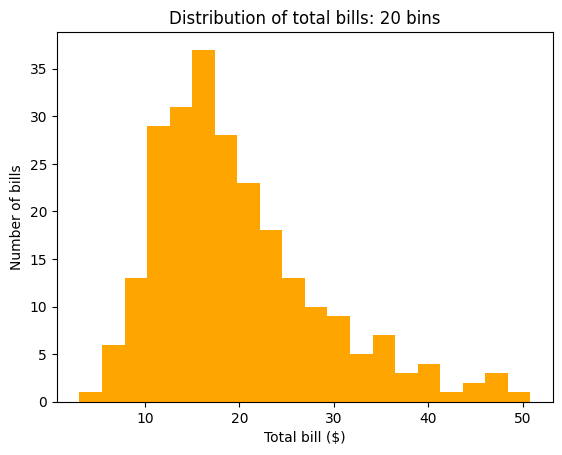

In [24]:
plt.figure()
plt.hist(tips["total_bill"], color="orange", bins=20)
plt.title("Distribution of total bills: 20 bins")
plt.xlabel("Total bill ($)")
plt.ylabel("Number of bills")
plt.show()

**EX16** Execute the following code and describe what it is representing.

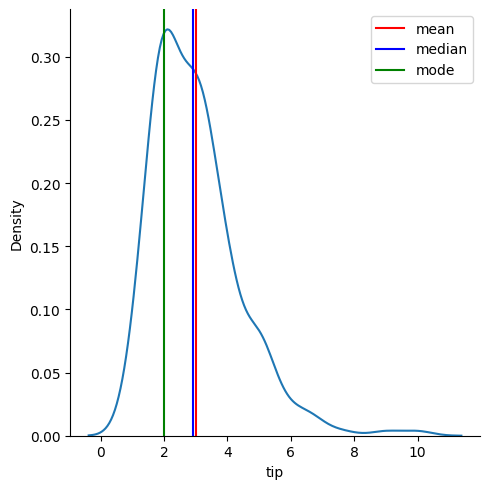

In [25]:
mean = tips["tip"].mean()
median = tips["tip"].median()
mode = tips["tip"].mode().iloc[0]
sns.displot(tips["tip"], kind="kde")
plt.axvline(mean, color="r", label="mean")
plt.axvline(median, color="b", label="median")
plt.axvline(mode, color="g", label="mode")
plt.legend()
plt.show()

**Answer:** The smooth curve estimates the distribution of tip amounts. The vertical lines mark the mean (about $3.00), median ($2.90), and mode ($2.00). The distribution has a right tail.

**EX17** Execute the following code and describe what it is representing.

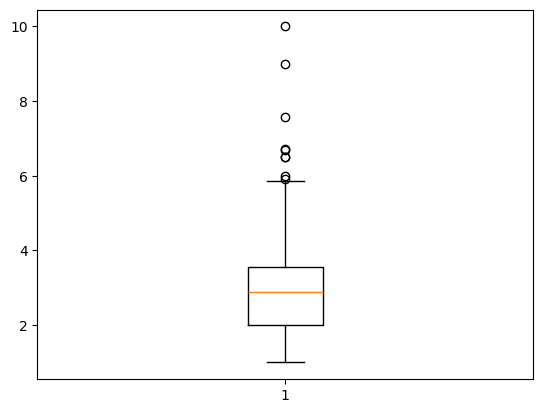

In [26]:
plt.boxplot(tips["tip"])
plt.show()

**Answer:** The box shows the middle 50% of tips, from the first to the third quartile. The line inside is the median. The whiskers extend to the most extreme values within 1.5 times the interquartile range. Points beyond them are potential outliers, mostly large tips.

**EX18** Build a boxplot of `tip` variable per day using sns.boxplot()

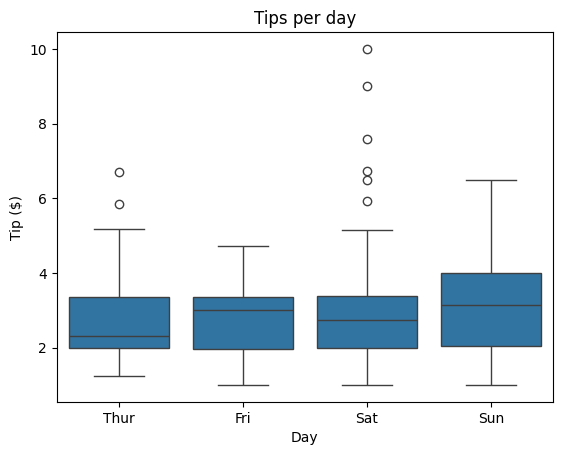

In [27]:
plt.figure()
sns.boxplot(data=tips, x="day", y="tip")
plt.title("Tips per day")
plt.xlabel("Day")
plt.ylabel("Tip ($)")
plt.show()

**EX19** Execute the following code and describe the visualization

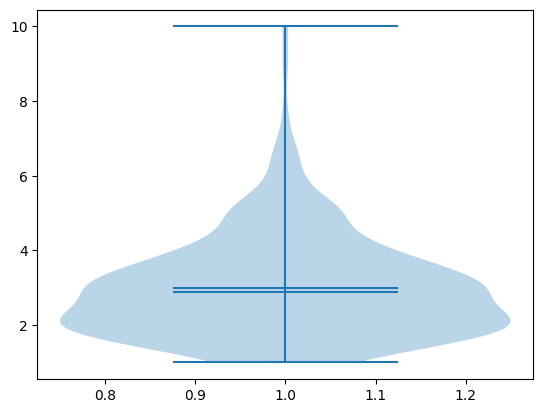

In [28]:
plt.violinplot(tips["tip"], showmeans=True, showmedians=True, showextrema=True)
plt.show()

**Answer:** The violin shows the estimated distribution of tip amounts. Wider sections mean more observations near that amount. The lines mark the mean, median, minimum, and maximum.

**EX20** Build a violin plot of the `tip` variable per day and differentiating the `sex`variable using sns.violinplot(x,y, hue="sex")

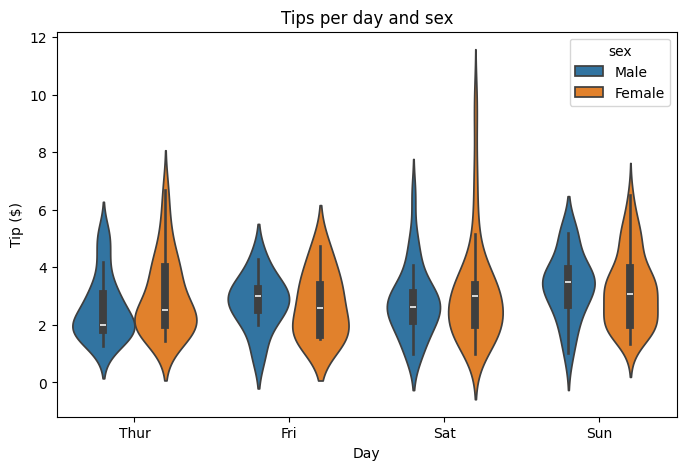

In [29]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=tips, x="day", y="tip", hue="sex")
plt.title("Tips per day and sex")
plt.xlabel("Day")
plt.ylabel("Tip ($)")
plt.show()

**EX21** Do females use to give more tips on Sundays? and on Saturdays? Justify your answer.

In [30]:
weekend = tips[tips["day"].isin(["Sun", "Sat"])]
weekend.groupby(["day", "sex"], observed=True)["tip"].agg(["count", "mean", "median"]).round(2)

count  mean  median
day sex                        
Sat Male       59  3.08    3.00
    Female     28  2.80    2.62
Sun Male       58  3.22    3.08
    Female     18  3.37    3.50

**Answer:** Using the mean tip, females give slightly more on Sundays ($3.37 versus $3.22 for males), but less on Saturdays ($2.80 versus $3.08). The groups overlap in the violin plot. These are sample averages of tip amounts, not tip percentages or proof of a general difference.

##**Plots to represent relationships between variables:**##

**Scatterplot**:

Scatter plots are used to observe relationships between variables and uses dots to represent the relationship between them.

*matplotlib function*: scatter(x, y)
*parameters*:

- c: Set the color of the markers.
- s: Set the size of the markers.
- marker: Set the marker style, e.g., circles, triangles, or squares.
- edgecolor: Set the color of the lines on the edges of the markers.


**Jointplot**:

Draw a plot of two variables with bivariate and univariate graphs.

*seaborn*: sns.jointplot (x, y, data).


**Correlation matrix**:
To represent the correlation matrix, we will create a heatmap in matplotlib and seaborn.

*matplotlib function*: plt.imshow(`correlation matrix`)

*seaborn*: sns.heatmap(`correlation matrix`)

**Pairplot**:

This function will create a grid of Axes such that each numeric variable in data will by shared across the y-axes across a single row and the x-axes across a single column. The diagonal plots are treated differently: a univariate distribution plot is drawn to show the marginal distribution of the data in each column.

*seaborn*: seaborn.pairplot()
*parameters*:

- kind: Kind of plot to make
- markerssingle:  matplotlib marker code or list
- huename of variable in data




**EX22** Execute this scatter plot and examine the results. Which insight do you get from it?

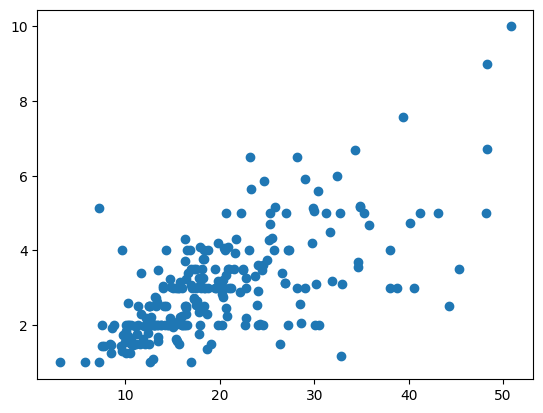

In [31]:
plt.scatter(tips["total_bill"], tips['tip'])
plt.show()

**Answer:** Larger bills generally have larger tips, so the relationship is positive. There is still variation: customers with similar bills can leave different tips.

**EX23** Repeat the previous exercise but adding the `s`=10, `marker`="o" and colour depending on the value of tips.total_bill. Add a title and X and Y labels.

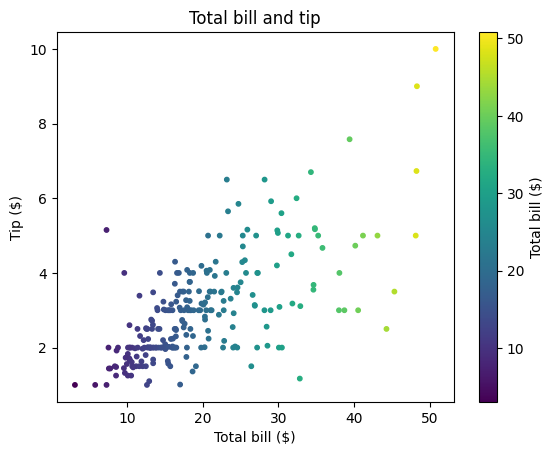

In [32]:
plt.figure()
points = plt.scatter(tips["total_bill"], tips["tip"], s=10,
                     marker="o", c=tips["total_bill"], cmap="viridis")
plt.colorbar(points, label="Total bill ($)")
plt.title("Total bill and tip")
plt.xlabel("Total bill ($)")
plt.ylabel("Tip ($)")
plt.show()

**EX23b** Repeat the previous exercise where the size of each sample depends on the value of the tip multiplied by a factor x10.

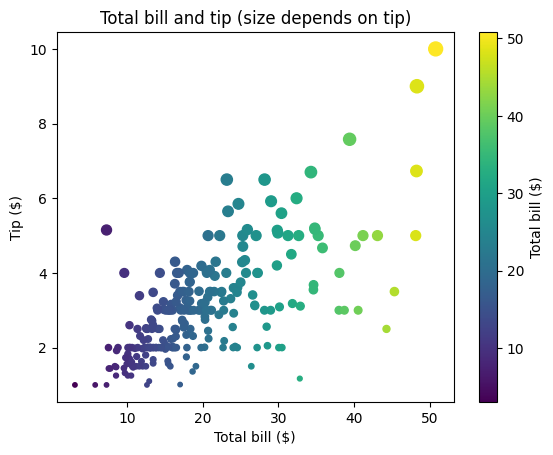

In [33]:
plt.figure()
points = plt.scatter(tips["total_bill"], tips["tip"], s=tips["tip"] * 10,
                     marker="o", c=tips["total_bill"], cmap="viridis")
plt.colorbar(points, label="Total bill ($)")
plt.title("Total bill and tip (size depends on tip)")
plt.xlabel("Total bill ($)")
plt.ylabel("Tip ($)")
plt.show()

**EX24**: Execute the following jointplot.

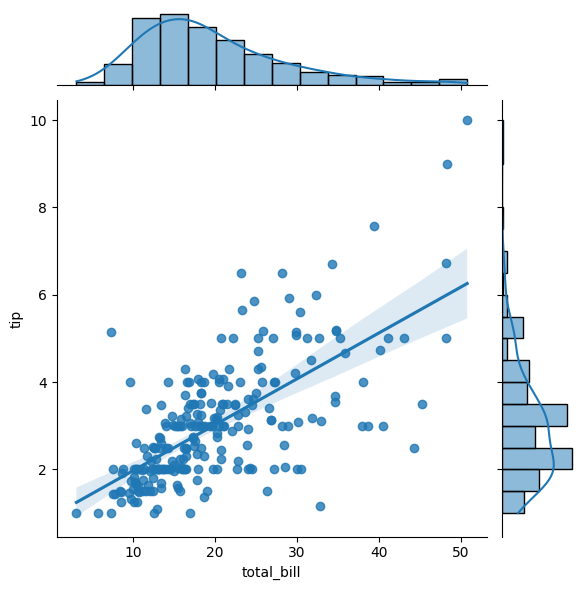

In [34]:
sns.jointplot(x="total_bill", y="tip", data=tips, kind="reg")

**Answer:** The center shows the relationship between total bill and tip, with a fitted regression line and its confidence band. The histograms at the edges show each variable separately.

**EX25**: Is the correlation between `total_bill`and `tip`similar between males and females? To answer this question build a sns.jointplot with hue="sex".

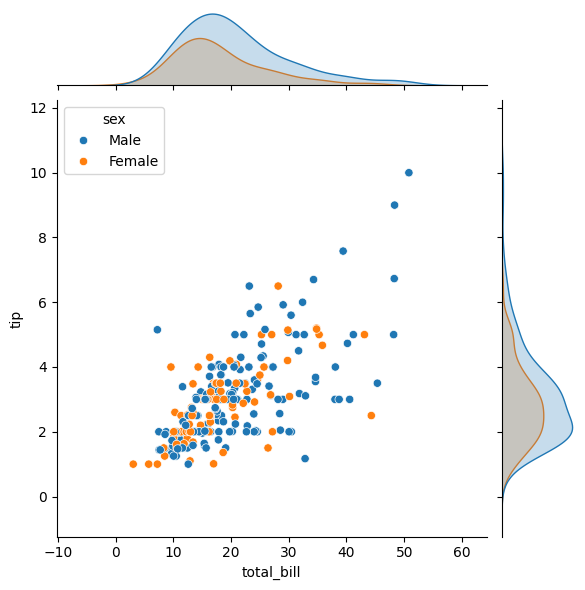

Male 0.67
Female 0.683


In [35]:
sns.jointplot(data=tips, x="total_bill", y="tip", hue="sex")
plt.show()
for sex in ["Male", "Female"]:
    group = tips[tips["sex"] == sex]
    print(sex, round(group["total_bill"].corr(group["tip"]), 3))

**Answer:** Yes. The correlation is positive and similar for males (about 0.670) and females (about 0.683). Larger bills tend to have larger tips in both groups.

**EX26** Execute the following and code. Which are the variable with more correlation? And with lower correlation?

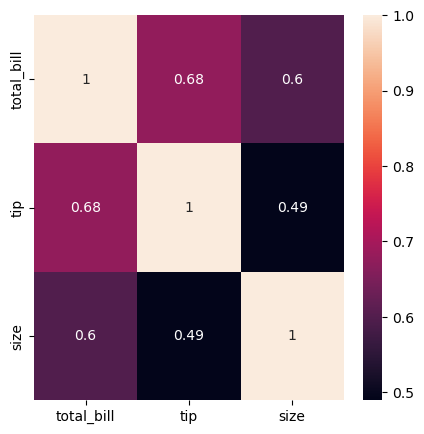

In [6]:
plt.figure(figsize=(5,5))
sns.heatmap(tips.corr(numeric_only=True),annot=True)
plt.show()


**Answer:** Ignoring the diagonal, total_bill and tip have the highest correlation (about 0.68). tip and size have the lowest (about 0.49). All three pairs have positive correlations.

**EX27** Execute the following visualization code. Are `total_bill`, `tip`and `size`variables with the same distribution between male and female?

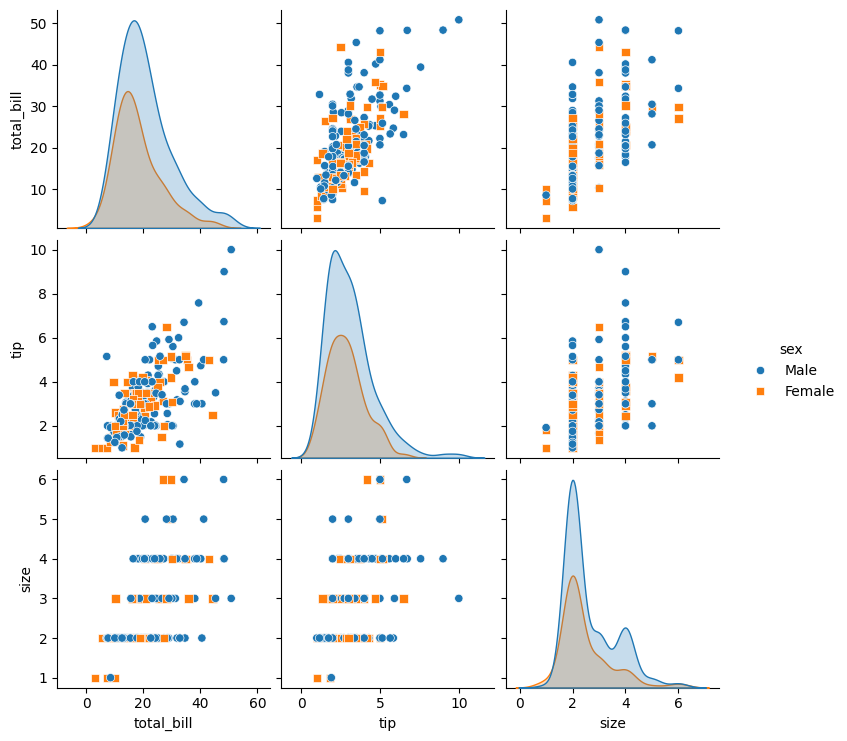

In [37]:
sns.pairplot(data=tips,hue='sex', markers=["o", "s"])
plt.show()

In [38]:
tips.groupby("sex", observed=True)[["total_bill", "tip", "size"]].describe().round(2)

total_bill                                                   tip        \
            count   mean   std   min    25%    50%    75%    max  count  mean   
sex                                                                             
Male        157.0  20.74  9.25  7.25  14.00  18.35  24.71  50.81  157.0  3.09   
Female       87.0  18.06  8.01  3.07  12.75  16.40  21.52  44.30   87.0  2.83   

        ...               size                                       
        ...   75%   max  count  mean   std  min  25%  50%  75%  max  
sex     ...                                                          
Male    ...  3.76  10.0  157.0  2.63  0.96  1.0  2.0  2.0  3.0  6.0  
Female  ...  3.50   6.5   87.0  2.46  0.94  1.0  2.0  2.0  3.0  6.0  

[2 rows x 24 columns]

**Answer:** The distributions have similar shapes and overlap, but they are not exactly the same. In this sample, males have higher average bills (about $20.74 versus $18.06), tips ($3.09 versus $2.83), and group sizes (2.63 versus 2.46). The plots and summaries describe this sample; they do not establish a difference in the wider population.

##**Multi-plots and subplots:**##

**Subplots**:

Build multiple charts in a figure.

*matplotlib* subplot(nrows, ncols, plot_number)
• nrows: The number of rows in the igure.
• ncols: The number of columns in the igure.
• plot_number: The placement of the chart (starts at 1).


In [39]:
# Copy the data before adding the encoded day column.
df1 = tips.copy()

In [40]:
# Assign an integer to each day in alphabetical order.
day_codes = {"Fri": 0, "Sat": 1, "Sun": 2, "Thur": 3}

In [41]:
df1["LE Day"] = df1["day"].map(day_codes).astype(int)

In [42]:
df1.head()

,total_bill,tip,sex,smoker,day,time,size,LE Day
0,16.99,1.01,Female,No,Sun,Dinner,2,2
1,10.34,1.66,Male,No,Sun,Dinner,3,2
2,21.01,3.50,Male,No,Sun,Dinner,3,2
3,23.68,3.31,Male,No,Sun,Dinner,2,2
4,24.59,3.61,Female,No,Sun,Dinner,4,2


**EX28**: Execute the following code. What are they representing?


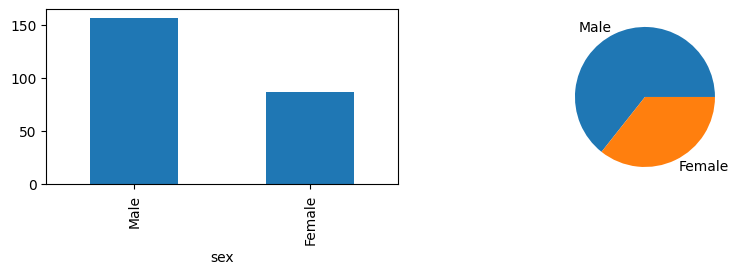

In [43]:
plt.figure(figsize=(10,5))
plt.subplot(2,2,1)
tips['sex'].value_counts().plot(kind='bar')
plt.subplot(2,2,2)
tips['sex'].value_counts().plot(kind='pie')
plt.show()

**Answer:** The bar chart shows the number of records by sex: 157 male and 87 female. The pie chart shows the same counts as shares of the dataset, about 64% male and 36% female. Both occupy the top row of a 2 by 2 layout.

**EX29**: Look at the following code. Its output is similar to the previous exercise but the subplots are swaped. Modify the code to have the same order: i.e. first subplot should be barplot and the second one, the pie chart.

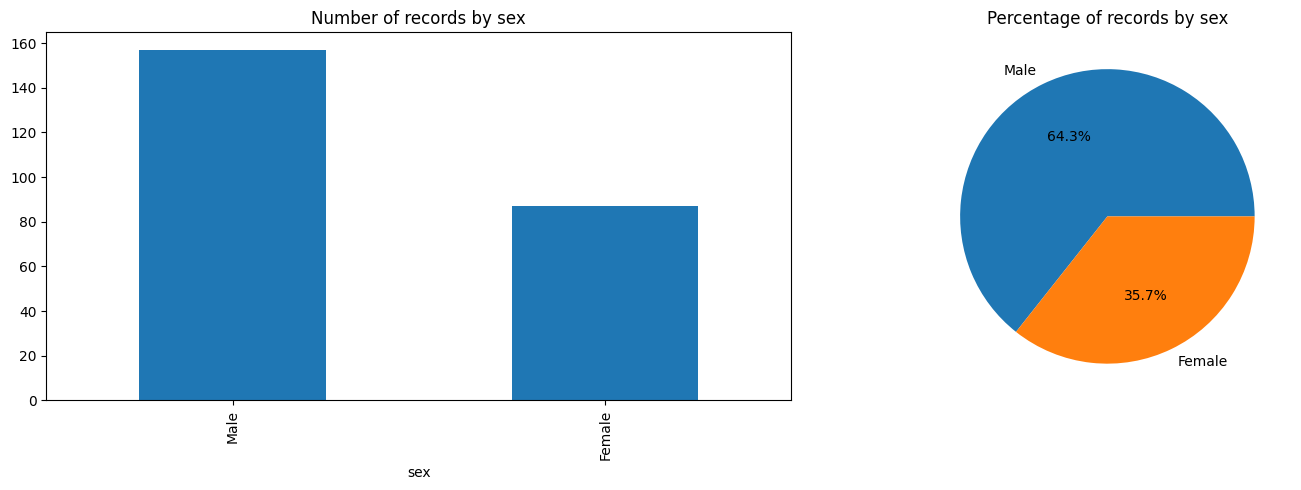

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
tips["sex"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Number of records by sex")
tips["sex"].value_counts().plot(kind="pie", ax=axes[1], autopct="%1.1f%%")
axes[1].set_title("Percentage of records by sex")
plt.tight_layout()
plt.show()

**Answer:** The bar chart is now on the left (axes[0]), and the pie chart is on the right (axes[1]).